# Exercise Sheet 1 – Lab Course Machine Learning


In [16]:
# Step 0: load the libraries (run once)
import sys
print(sys.executable)

/usr/local/bin/python3


In [ ]:
!pip install pandas
!pip install scipy


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [18]:
!pip install seaborn


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [19]:
# Step 0: load the libraries (run once) 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

%matplotlib inline

## 1.1 Heights and weights

In [20]:
# Load the data and pick the height and weight columns
data = pd.read_csv("heights_weights.csv")
print(data.columns.tolist())

height = data[[c for c in data.columns if "height" in c.lower()][0]].to_numpy()
weight = data[[c for c in data.columns if "weight" in c.lower()][0]].to_numpy()

# (a) mean and standard deviation
print("Height -> mean:", round(height.mean(), 2), " std:", round(height.std(), 2))
print("Weight -> mean:", round(weight.mean(), 2), " std:", round(weight.std(), 2))

['Index', 'Height(Inches)', 'Weight(Pounds)']
Height -> mean: 67.99  std: 1.9
Weight -> mean: 127.08  std: 11.66


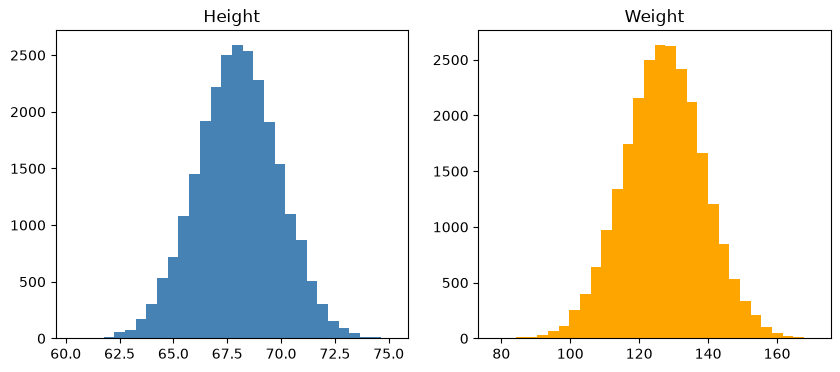

In [21]:
# (b) histograms: how are the values spread?
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(height, bins=30, color="steelblue")
axes[0].set_title("Height")
axes[1].hist(weight, bins=30, color="orange")
axes[1].set_title("Weight")
plt.show()

In [22]:
# (c) correlation from scratch:  r = sum(dx*dy) / sqrt(sum(dx^2) * sum(dy^2))
dx = height - height.mean()      # distance of each height from its mean
dy = weight - weight.mean()      # distance of each weight from its mean

r = np.sum(dx * dy) / np.sqrt(np.sum(dx**2) * np.sum(dy**2))
print("Correlation:", round(r, 4))
print("Check with NumPy:", round(np.corrcoef(height, weight)[0, 1], 4))

Correlation: 0.5029
Check with NumPy: 0.5029


**Comments:** both variables look bell-shaped. The correlation is positive: taller people tend to weight more.

## 1.2 Bacteria growth
**Task:** fit the curve  `y = a · e^(b·t)`  with `curve_fit`, plot it, and measure the quality with R².

In [23]:
from scipy.optimize import curve_fit

hours  = np.array([0, 1, 2, 3, 4, 5])
counts = np.array([100, 180, 324, 583.2, 1049.76, 1889.57])

def growth(t, a, b):
    return a * np.exp(b * t)

# curve_fit finds the a and b that fit the data best
(a, b), _ = curve_fit(growth, hours, counts)
print("a =", round(a, 2), " (starting)")
print("b =", round(b, 3), " (growth rate)")

a = 100.0  (starting)
b = 0.588  (growth rate)


R^2 = 1.0


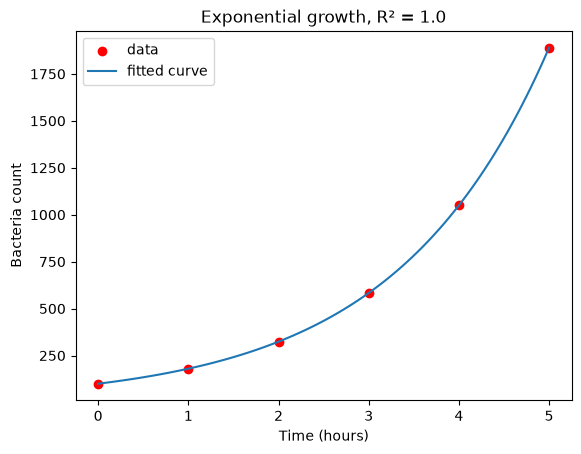

In [24]:
# R^2 = 1 - (error of our model) / (error of just using the mean)
predicted = growth(hours, a, b)
r2 = 1 - np.sum((counts - predicted)**2) / np.sum((counts - counts.mean())**2)
print("R^2 =", round(r2, 4))

# plot data points and fitted curve
smooth = np.linspace(0, 5, 100)
plt.scatter(hours, counts, color="red", label="data")
plt.plot(smooth, growth(smooth, a, b), label="fitted curve")
plt.xlabel("Time (hours)")
plt.ylabel("Bacteria count")
plt.title("Exponential growth, R² = " + str(round(r2, 4)))
plt.legend()
plt.show()

**Comment:** a ≈ 100 and b ≈ 0.59, so the bacteria grow about 80% per hour (e^0.588 ≈ 1.8). R² ≈ 1 means the model fits almost perfectly.

## 1.3 Rotating torus
**Task:** build the torus from its formula (R = 5, r = 2), then turn it a little in every frame around the z-axis and save a GIF.

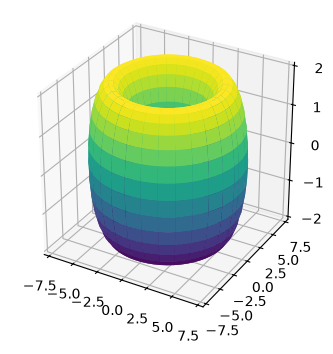

In [25]:
from matplotlib.animation import FuncAnimation, PillowWriter

R, r = 5, 2
u, v = np.meshgrid(np.linspace(0, 2*np.pi, 60), np.linspace(0, 2*np.pi, 30))

# parametric equations of the torus
x = (R + r*np.cos(v)) * np.cos(u)
y = (R + r*np.cos(v)) * np.sin(u)
z = r * np.sin(v)

# (b) static 3D plot
fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(x, y, z, cmap="viridis")
ax.set_box_aspect((1, 1, 1))
plt.show()

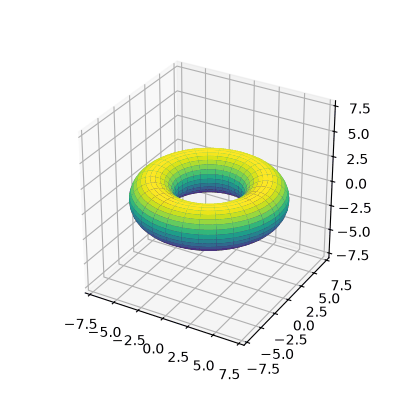

In [26]:
# (c) + (d) animation: 100 frames at 10 frames/second = 10 seconds
fps = 10
frames = 100

fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot(projection="3d")

def draw(frame):
    ax.clear()
    angle = 2 * np.pi * frame / frames          # how far we have turned so far
    x_new = x*np.cos(angle) - y*np.sin(angle)   # rotation around z: only x and y change
    y_new = x*np.sin(angle) + y*np.cos(angle)
    ax.plot_surface(x_new, y_new, z, cmap="viridis")
    ax.set_xlim(-8, 8); ax.set_ylim(-8, 8); ax.set_zlim(-8, 8)
    ax.set_box_aspect((1, 1, 1))

animation = FuncAnimation(fig, draw, frames=frames)
animation.save("torus.gif", writer=PillowWriter(fps=fps))
plt.close(fig)
display(Image(filename="torus.gif"))

**Comments:** rotating around z only changes x and y. z stays the same, so the torus spins like a wheel lying flat.

## 2.1 Flights from and to Austin
**Task:** load the data, then answer four questions with one simple plot each.

In [27]:
flights = pd.read_csv("task1.txt", sep=None, engine="python")
flights.info()           # columns, types, missing values
flights.head()

<class 'pandas.DataFrame'>
RangeIndex: 99260 entries, 0 to 99259
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               99260 non-null  int64  
 1   Month              99260 non-null  int64  
 2   DayofMonth         99260 non-null  int64  
 3   DayOfWeek          99260 non-null  int64  
 4   DepTime            97847 non-null  float64
 5   CRSDepTime         99260 non-null  int64  
 6   ArrTime            97693 non-null  float64
 7   CRSArrTime         99260 non-null  int64  
 8   UniqueCarrier      99260 non-null  str    
 9   FlightNum          99260 non-null  int64  
 10  TailNum            98156 non-null  str    
 11  ActualElapsedTime  97659 non-null  float64
 12  CRSElapsedTime     99249 non-null  float64
 13  AirTime            97659 non-null  float64
 14  ArrDelay           97659 non-null  float64
 15  DepDelay           97847 non-null  float64
 16  Origin             99260 non-null

,Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,ArrTime,CRSArrTime,UniqueCarrier,FlightNum,...,TaxiIn,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2008,1,1,2,120.0,1935,309.0,2130,9E,5746,...,3.0,18.0,0,NaN,0,339.0,0.0,0.0,0.0,0.0
1,2008,1,1,2,555.0,600,826.0,835,AA,1614,...,7.0,11.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN
2,2008,1,1,2,600.0,600,728.0,729,YV,2883,...,7.0,16.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN
3,2008,1,1,2,601.0,605,727.0,750,9E,5743,...,4.0,12.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN
4,2008,1,1,2,601.0,600,654.0,700,AA,1157,...,5.0,10.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN


In [28]:
# Parameters
TIME    = "CRSArrTime"       # planned departure time
AIRLINE = "UniqueCarrier"
DEST    = "Dest"
DELAY   = "ArrDelay"         # delay in minutes
Month = "Month"

flights["month"] = flights[Month]
flights["hour"]  = flights[TIME] // 100

# flights that LEAVE Austin
leaving = flights[flights["Origin"] == "AUS"]

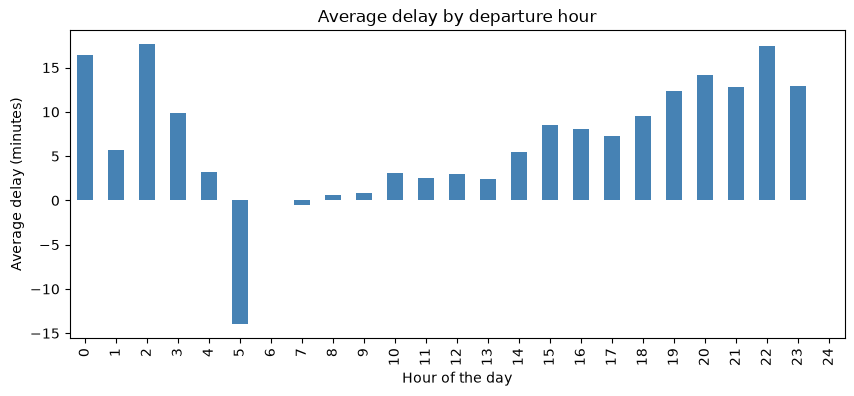

In [29]:
# Q1: What time of day has the fewest delays? 
by_hour = flights.groupby("hour")[DELAY].mean()
by_hour.plot(kind="bar", color="steelblue", figsize=(10, 4))
plt.title("Average delay by departure hour")
plt.xlabel("Hour of the day")
plt.ylabel("Average delay (minutes)")
plt.show()



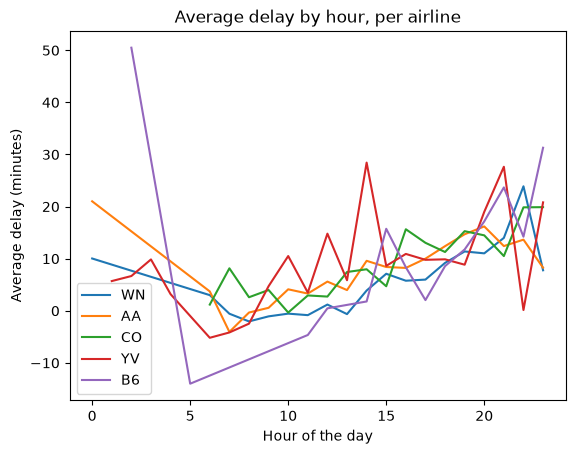

In [30]:
#Does it depend on the airline?
# same thing for the 5 biggest airlines
top_airlines = flights[AIRLINE].value_counts().head(5).index
for name in top_airlines:
    part = flights[flights[AIRLINE] == name]
    plt.plot(part.groupby("hour")[DELAY].mean(), label=name)
plt.title("Average delay by hour, per airline")
plt.xlabel("Hour of the day"); plt.ylabel("Average delay (minutes)")
plt.legend()
plt.show()

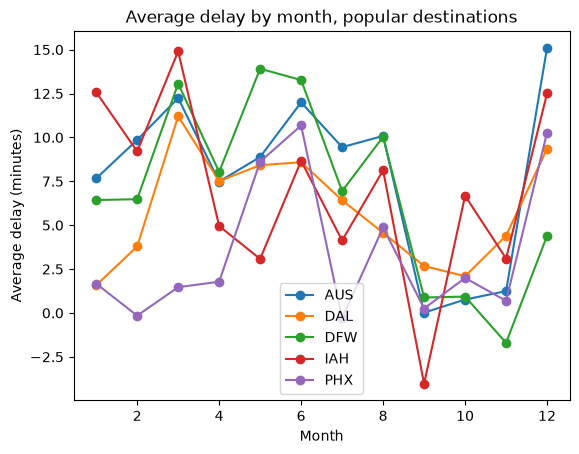

In [31]:
# Q2: Which time of the year is best? Does the destination matter?
top_dest = flights[DEST].value_counts().head(5).index      # 5 most popular destinations
for name in top_dest:
    part = flights[flights[DEST] == name]
    plt.plot(part.groupby("month")[DELAY].mean(), marker="o", label=name)
plt.title("Average delay by month, popular destinations")
plt.xlabel("Month"); plt.ylabel("Average delay (minutes)")
plt.legend()
plt.show()

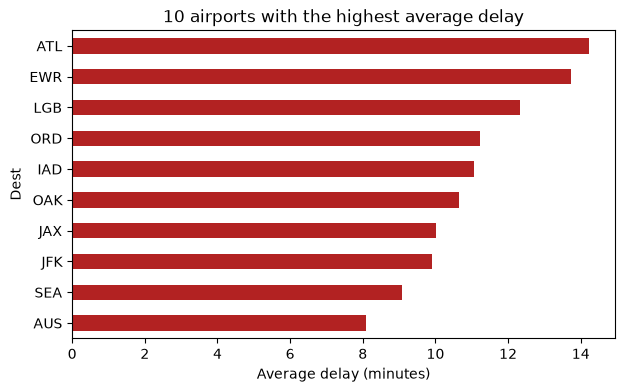

In [32]:
# Q3: Which airports are bad to fly to?  (only airports with at least 100 flights)
counts = flights[DEST].value_counts()
big = flights[flights[DEST].isin(counts[counts >= 100].index)]
worst = big.groupby(DEST)[DELAY].mean().sort_values().tail(10)

worst.plot(kind="barh", color="firebrick", figsize=(7, 4))
plt.title("10 airports with the highest average delay")
plt.xlabel("Average delay (minutes)")
plt.show()

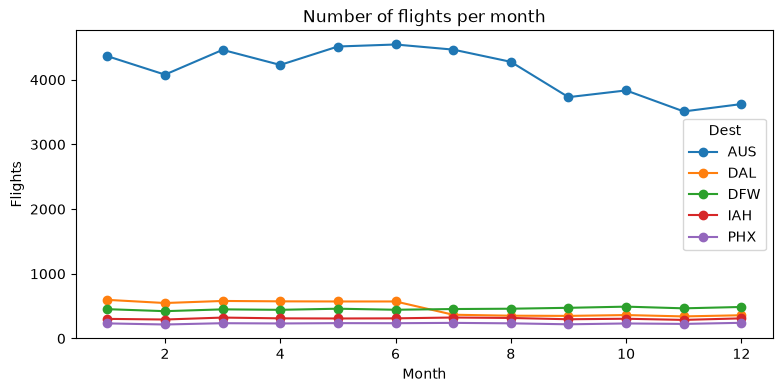

In [33]:
# Q4: How do the number of flights to each destination change over the year?
per_month = flights[flights[DEST].isin(top_dest)].groupby(["month", DEST]).size().unstack()
per_month.plot(marker="o", figsize=(9, 4))
plt.title("Number of flights per month")
plt.xlabel("Month"); plt.ylabel("Flights")
plt.show()

**Comments:** * Early morning is best, Delays pile up in the evening; Summer and December are worst)*

## 2.2 Olympic medallists
**Task:** Questions about heights and ages.

In [34]:
olympics = pd.read_csv("task2.txt", sep=None, engine="python")
olympics.info()
print(olympics["sex"].unique())     # are the values 'F'/'M' or 'Female'/'Male'?
olympics.head()

<class 'pandas.DataFrame'>
RangeIndex: 23850 entries, 0 to 23849
Data columns (total 15 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      23850 non-null  int64  
 1   name    23850 non-null  str    
 2   sex     23850 non-null  str    
 3   age     23850 non-null  int64  
 4   height  23850 non-null  int64  
 5   weight  23850 non-null  float64
 6   team    23850 non-null  str    
 7   noc     23850 non-null  str    
 8   games   23850 non-null  str    
 9   year    23850 non-null  int64  
 10  season  23850 non-null  str    
 11  city    23850 non-null  str    
 12  sport   23850 non-null  str    
 13  event   23850 non-null  str    
 14  medal   23850 non-null  str    
dtypes: float64(1), int64(4), str(10)
memory usage: 2.7 MB
<StringArray>
['M', 'F']
Length: 2, dtype: str


,id,name,sex,age,height,weight,team,noc,games,year,season,city,sport,event,medal
0,16,Juhamatti Tapio Aaltonen,M,28,184,85.0,Finland,FIN,2014 Winter,2014,Winter,Sochi,Ice Hockey,Ice Hockey Men's Ice Hockey,Bronze
1,17,Paavo Johannes Aaltonen,M,28,175,64.0,Finland,FIN,1948 Summer,1948,Summer,London,Gymnastics,Gymnastics Men's Individual All-Around,Bronze
2,17,Paavo Johannes Aaltonen,M,28,175,64.0,Finland,FIN,1948 Summer,1948,Summer,London,Gymnastics,Gymnastics Men's Team All-Around,Gold
3,17,Paavo Johannes Aaltonen,M,28,175,64.0,Finland,FIN,1948 Summer,1948,Summer,London,Gymnastics,Gymnastics Men's Horse Vault,Gold
4,17,Paavo Johannes Aaltonen,M,28,175,64.0,Finland,FIN,1948 Summer,1948,Summer,London,Gymnastics,Gymnastics Men's Pommelled Horse,Gold


In [35]:
WOMEN = "F"      # change to "Female" if needed
MEN   = "M"      # change to "Male" if needed

# (Q1) 95th percentile of height of women in Athletics
women_athletics = olympics[(olympics["sex"] == WOMEN) & (olympics["sport"] == "Athletics")]
print("95% of these women are shorter than:", women_athletics["height"].quantile(0.95), "cm")



95% of these women are shorter than: 183.0 cm


In [36]:
# (Q2) women's event with the most different heights (largest standard deviation)
women = olympics[olympics["sex"] == WOMEN]
spread = women.groupby("event")["height"].std()
print("Most variable event:", spread.idxmax(), "| std =", round(spread.max(), 2))

Most variable event: Rowing Women's Coxed Fours | std = 10.87


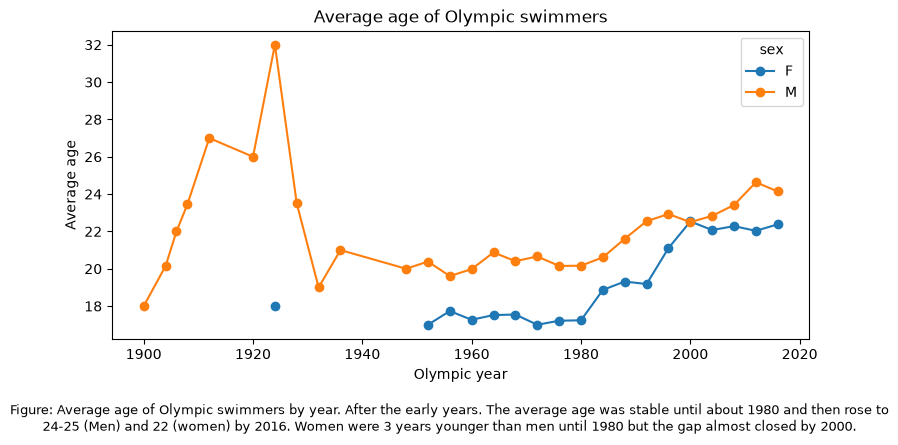

In [37]:
# (Q3) average age of swimmers over time, men vs women
swimmers = olympics[olympics["sport"] == "Swimming"]
age_over_time = swimmers.groupby(["year", "sex"])["age"].mean().unstack()

age_over_time.plot(marker="o", figsize=(9, 4))
plt.title("Average age of Olympic swimmers")
plt.xlabel("Olympic year"); plt.ylabel("Average age")
plt.figtext(0.5, -0.12,
    "Figure: Average age of Olympic swimmers by year. After the early years. The average age was stable until about 1980 and then rose to 24-25 (Men) and 22 (women) by 2016. Women were 3 years younger than men until 1980 but the gap almost closed by 2000.",
    ha="center", wrap=True, fontsize=9)
plt.show()